Numerical method halted likely due to the occurance of an infinite loop, this may impact the accuracy of the results.
All values satisfy the eigenvalue equation
Energy at n = 0 0.4996809513018151 ℏω, Expected value: 0.5 ℏω, Percentage error 0.06380973963697745
Energy at n = 1 1.4984039406872636 ℏω, Expected value: 1.5 ℏω, Percentage error 0.10640395418242872
Energy at n = 2 2.495847901829947 ℏω, Expected value: 2.5 ℏω, Percentage error 0.16608392680211637
Energy at n = 3 3.4920107915462637 ℏω, Expected value: 3.5 ℏω, Percentage error 0.2282630986781799
Energy at n = 4 4.486894261425652 ℏω, Expected value: 4.5 ℏω, Percentage error 0.2912386349855072
Energy at n = 5 5.4805257505165414 ℏω, Expected value: 5.5 ℏω, Percentage error 0.35407726333561
Energy at n = 6 6.473069760409093 ℏω, Expected value: 6.5 ℏω, Percentage error 0.4143113783216497
Energy at n = 7 7.465250998930165 ℏω, Expected value: 7.5 ℏω, Percentage error 0.4633200142644611
Energy at n = 8 8.459534295041061 ℏω, Expected val

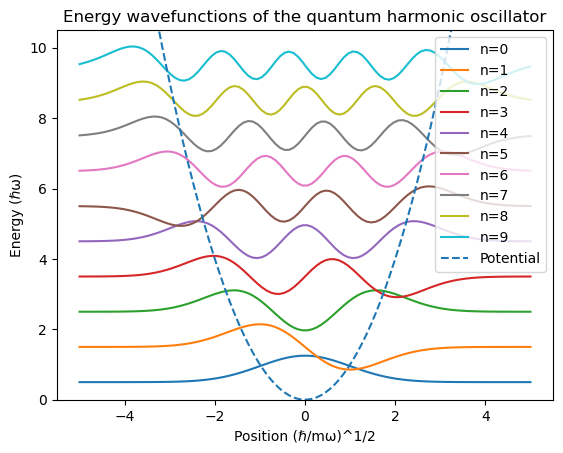

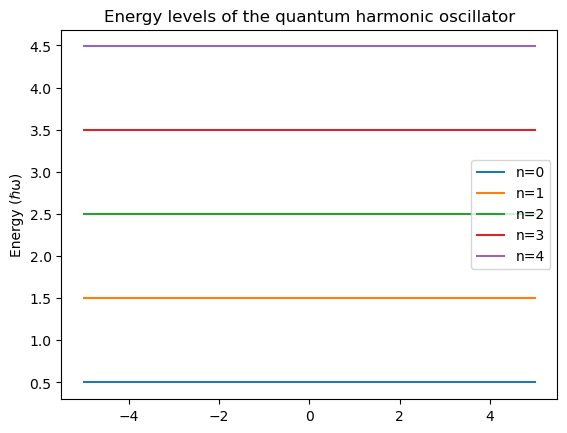

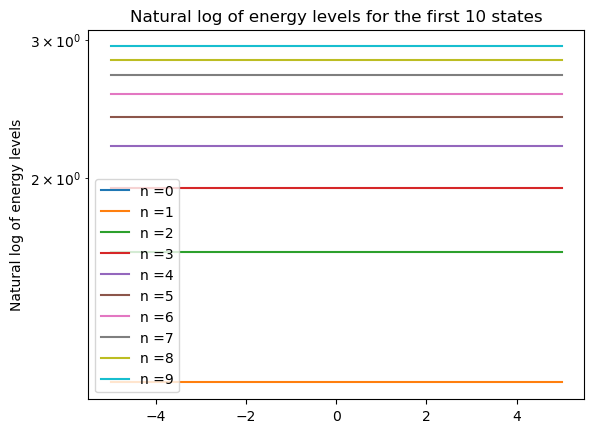

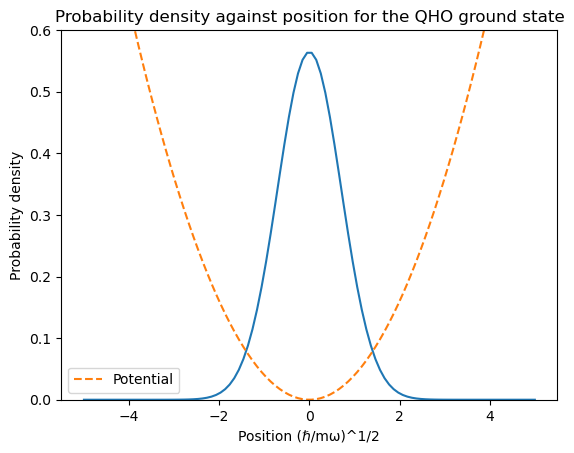

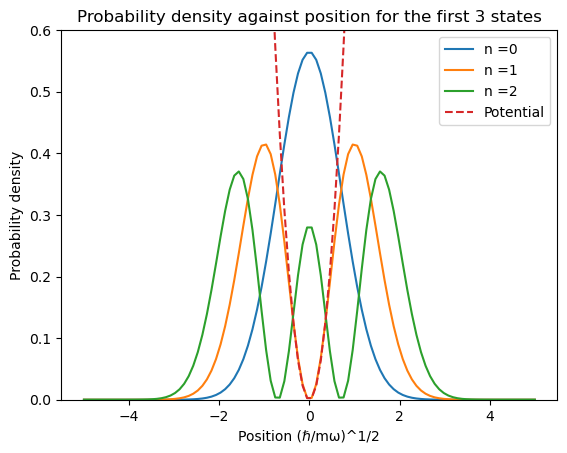

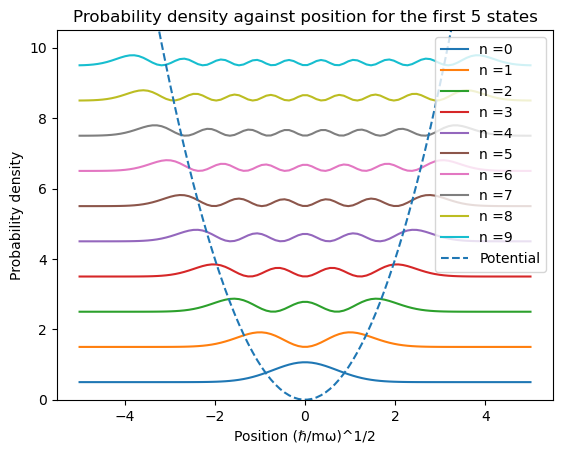

In [1]:
## Quantum Harmonic Oscillator ##
## imports
import numpy as np
import scipy
import scipy.linalg as linalg
from scipy.linalg import lu_factor , lu_solve
import matplotlib.pyplot as plt

## functions
def find_eigenvalues(a):
    """
    This function takes an NxN array a and returns an Nx1 array of eigenvalues and an NxN array of eigenvectors associated with the provided array through power iteration and hotelling deflation
    """
    all_eigenvectors = [] #creates empty lists to store the eigenvalues and eigenvectors found
    all_eigenvalues = []
    for i in range (N):
        eigenvectors_guess = np.random.rand(len(a)) #begins with a random guess of each value in an eigenvector of matrix a
        correct_to_8dp = False 
        prev_it = np.zeros(len(a)) #creates an array of zeros which the last iterations results can be stored in to check for convergence
        iterations = 0 #this adds a layer of protection in case the function gets stuck in an infinite loop so that the rest of the eigensolutions can continue to be calculated
        while not correct_to_8dp and iterations < 50000:
            unnormalised_solution_eigenvectors = (a)@eigenvectors_guess #uses power iteration on the current guess to get a new guess for the eigenvector
            prev_it = eigenvectors_guess #sets the previous guess to prev_it so we can check if the iterations are converging
            eigenvectors_guess = unnormalised_solution_eigenvectors/np.linalg.norm(unnormalised_solution_eigenvectors) #normalises the power iteration
            #linalg.norm() taken from ChatGPT, prompt: 'how to get modulus of a matrix if matrix is represented by an array' 
            if np.linalg.norm(prev_it - eigenvectors_guess)<1e-8: #checks whether this iteration shares the first 8 decimal points with the previous iteration
                #np.linalg.norm() taken from ChatGPT from the prompt 'how to find the magnitude of an array'
                correct_to_8dp = True #if the iterations have converged to 8 decimal places then correct_to_8dp is set to true, stopping the while loop
            elif np.linalg.norm(prev_it + eigenvectors_guess)<1e-8: #also checks for convergence of the iterations in the case that these eigenvectors have differing signs but similar absaolute values
                #np.linalg.norm() taken from ChatGPT from the prompt 'how to find the magnitude of an array'
                correct_to_8dp = True
            else:
                iterations += 1
            if iterations == 50000: #this warns the user that the power iteration has been halted to stop a potential infinite loop rather than due to accuracy of the iteration and so the results may suffer because of this
                print('Numerical method halted likely due to the occurance of an infinite loop, this may impact the accuracy of the results.')
        eigenvalue_guess = (np.transpose(eigenvectors_guess)@a@eigenvectors_guess)/(np.transpose(eigenvectors_guess)@eigenvectors_guess) #calculates the eigenvalues associate with the last found eigenvector from the Rayleigh Quotient
        all_eigenvectors.append(eigenvectors_guess) #stores the most recently found eigenvector to the eigenvectors array
        all_eigenvalues.append(eigenvalue_guess) #stores the associated eigenvalue in the eigenvalues array
        a = a - eigenvalue_guess*np.outer(eigenvectors_guess,eigenvectors_guess) #uses hotelling deflation to remove that eigenpair so that the process can be repeated to find another eigenpair
    return np.flip(np.array(all_eigenvectors)), np.flip(np.array(all_eigenvalues)) #returns a numpy array of all the eigenvectors and their associated eigenvalues of matrix a
    #flips the eigenvalue array as power iteration tends to find the eigenpairs in order of largest to smallest and it is more useful for this code to have them in order of smallest to largest so the n=0 solution is first in the array
    
def check_results(a,b,c):
    """
    This function takes 3 arrays:
    a - a square NxN matrix 
    b - an NxN matrix containing all the eigenvectors for a
    c - an Nx1 matrix containing the eigenvalues associated with each eigenvector in b

    and then prints 'CORRECT' if each matrix equation ab=cb holds true for each eigenvector eigenvalue pair. 
    If this does not hold true then it prints the number of the element in arrays b and c which are incorrect and 
    ab-bc so that the user can see whether it is caused by a floating point rounding error.
    """
    all_correct = True
    for i in range (len(a)):
        left_hand_side = a@b[i] #computes the left hand side of the eigenvector equation by a matrix multiplication on the matrix which the eigenpairs are associated with, and an eigenvector of it
        right_hand_side = c[i]*b[i] #computes the right hand side of the eigenvector equation by multiplying the eigenvector used in the line above with its associated eigenvalue
        if np.all(np.sqrt(left_hand_side**2) - np.sqrt(right_hand_side**2)>1e-3): #checks if the eigenvector equation holds true by testing if the difference between them is less than 1e-3, floating point rounding errors means they are unlikely to ever be exactly equal
            print("TEST",i+1,"INCORRECT") #informs the user if the eigenpair in question is not valid
            print("DIFFERENCE:",np.sqrt(left_hand_side**2) - np.sqrt(right_hand_side**2)) #prints the difference between the two sides of the eigenvector equation so the user can see whether the error is due to floating point rounding errors or the calculation of the eigenpair
            all_correct = False
    if all_correct == True:
        print("All values satisfy the eigenvalue equation") #if every eigenpair succesfully fits the eigenvector equation then it informs the user all the eigenpairs are correct

## defining variables
N = 100 #initialises how many discrete points the spacial dimension will be split into
x = 5
x_i = np.linspace(-x,x,N) #creates an array containing the value of x at every discrete point 
delta_x = (2*x)/(N-1) #computes the spacing between x_i and x_i+1 as this is useful in future calculations
v_x_i = x_i**2 #creates an array containing the potential energy of the quantum harmonic oscillator at each discrete point

## kinetic energy calculations
QHO_kinetic_energy_matrix = np.zeros([N,N]) #creates an NxN numpy array to store the kinetic energy matrix that will be used to compute the hamiltonian
for i in range (N):
    QHO_kinetic_energy_matrix[i,i] = 2/(delta_x**2) #sets every value in the main diaganol to 2/delta x^2, as described in the assignment brief
    if i<(N-1):
        QHO_kinetic_energy_matrix[i,i+1] = (-1)/(delta_x**2) #sets every value on the diagonals either side of this to -1/delta x^2, as described in the assignment brief
    if i>0:
        QHO_kinetic_energy_matrix[i,i-1] = (-1)/(delta_x**2)

## potential energy calculations
QHO_potential_energy_matrix = np.zeros([N,N]) #creates a matrix with the potential at each discrete point on the diaganol and all other values set to 0, as desrcibed in the assignment brief
for i in range (N):
    QHO_potential_energy_matrix[i,i] = v_x_i[i]

## hamiltonian calculations
QHO_hamiltonian = QHO_kinetic_energy_matrix + QHO_potential_energy_matrix #calculates the hamiltonian by summing the kinetic and potential energies at every discrete point

## finding eigenvalues
QHO_wavefunctions, QHO_energies = find_eigenvalues(QHO_hamiltonian) #calls the find_eigenvalues function to return all the eigenpairs for the hamiltonian using power iteration and hotelling deflation

## normalising the wavefunctions
for n in range(len(QHO_wavefunctions)): #ensures normalisation of the wavefunctions
    norm = np.sum(QHO_wavefunctions[n]**2) * delta_x #calculates the normalisation factor for each wavefunction found
    QHO_wavefunctions[n] /= np.sqrt(norm) #normalises each wavefunction through dividing by the normalisation factor
    
## finding probability density
QHO_probability_density = (QHO_wavefunctions)**2 #calculates the probability density of the QHO by squaring each wavefunction

## checking results
check_results(QHO_hamiltonian,QHO_wavefunctions,QHO_energies) #checks if the eigenvector equation holds true for all the hamiltonian and each of the eigenpairs found for it

## displaying results
for i in range (10):#prints the first 10 energy levels of the QHO so they can be compared to the known energies of these QHO states
    print('Energy at n =',i,QHO_energies[i]*0.5,'ℏω, Expected value:',i+0.5,'ℏω, Percentage error',((i+0.5-QHO_energies[i]*0.5)/(i+0.5))*100) #the energy levels are multiplied by a factor of a half so that the units can be displayed as ℏω rather tha 1/2 ℏω for ease of reading
    
## plotting results
plt.figure()
for n in range (10): 
    name = 'n='+str(n)
    plt.plot(x_i,QHO_wavefunctions[n,:]+n+0.5,label=name) #plots the first ten wavefunctions against position, with each wavefunction slightly elevated for viewing purposes
plt.plot(x_i,np.diag(QHO_potential_energy_matrix), label = 'Potential', linestyle='dashed') #plots the potential energy against position on the same diagram as this is directly linked to the wavefunctions and can help to confirm the accuracy of the results
plt.ylim(0,10.5) #limits the y axis as the potential energy matrix contains much greater values than that of the wavefunctions, this ensures all elements can be clearly seen
plt.xlabel('Position (ℏ/mω)^1/2')
plt.ylabel('Energy (ℏω)')
plt.title('Energy wavefunctions of the quantum harmonic oscillator')
plt.legend()
plt.show()

plt.figure()
for m in range(5):
    name = 'n='+str(m)
    plt.plot(x_i,(QHO_energies[m]*0.5)*np.ones(N),label=name) #plots and labels the first 5 energies on a plot to help visualise the levels of quantisation
plt.ylabel('Energy (ℏω)')
plt.title('Energy levels of the quantum harmonic oscillator')
plt.legend()
plt.show()

plt.figure()
for o in range (10):
    name = 'n ='+str(o)
    plt.plot(x_i, np.log(QHO_energies[o])*np.ones(N), label = name) #plots and labels the natural log of the first ten energies in order to further visualise quantisation
plt.legend()
plt.ylabel('Natural log of energy levels')
plt.yscale('log')
plt.title('Natural log of energy levels for the first 10 states')
plt.show()

plt.figure()
plt.plot(x_i, QHO_probability_density[0]) #plots the probability density against position for the ground state only in order to clearly display this level
plt.plot(x_i,np.diag(QHO_potential_energy_matrix)/np.max(QHO_potential_energy_matrix), label = 'Potential', linestyle='dashed') #superimposes the potential energy at each point on the plot also so that it can be clearly visualised how the potential impacts the probability density
plt.legend()
plt.ylim(0,0.6)
plt.xlabel('Position (ℏ/mω)^1/2')
plt.ylabel('Probability density')
plt.title('Probability density against position for the QHO ground state')
plt.show()

plt.figure()
for o in range (3):
    name = 'n ='+str(o)
    plt.plot(x_i, QHO_probability_density[o], label = name) #plots to probability density of the first 3 wavefunctions for comparison to known results
plt.plot(x_i,np.diag(QHO_potential_energy_matrix), label = 'Potential', linestyle='dashed') #superimposes the potential energy at each point on the plot also so that it can be clearly visualised how the potential impacts the probability density
plt.legend()
plt.ylim(0,0.6) #limits the y axis at the top of the porbability density values in order to achieve clear visualisation as the potential energy has much higher values
plt.xlabel('Position (ℏ/mω)^1/2')
plt.ylabel('Probability density')
plt.title('Probability density against position for the first 3 states')
plt.show()

plt.figure()
for o in range (10):
    name = 'n ='+str(o)
    plt.plot(x_i, QHO_probability_density[o]+o+0.5, label = name) #plots to probability density of the first 10 wavefunctions in the style of the plot of the first ten wavefunctions for comparison to known results
plt.plot(x_i,np.diag(QHO_potential_energy_matrix), label = 'Potential', linestyle='dashed') #superimposes the potential energy at each point on the plot also so that it can be clearly visualised how the potential impacts the probability density
plt.legend()
plt.ylim(0,10.5) #limits the y axis at the top of the porbability density values in order to achieve clear visualisation as the potential energy has much higher values
plt.xlabel('Position (ℏ/mω)^1/2')
plt.ylabel('Probability density')
plt.title('Probability density against position for the first 5 states')
plt.show()

Hamiltonian is hermitian
Energy at n = 1 -0.9984050996113241 (m e^4/2 (4πϵ)^2 ℏ^2), Expected value: -1.0 (m e^4/2 (4πϵ)^2 ℏ^2), Percentage error 0.1594900388675935
Energy at n = 2 -0.24990007991911964 (m e^4/2 (4πϵ)^2 ℏ^2), Expected value: -0.25 (m e^4/2 (4πϵ)^2 ℏ^2), Percentage error 0.0024980020220090327
Energy at n = 3 -0.11108881916100953 (m e^4/2 (4πϵ)^2 ℏ^2), Expected value: -0.1111111111111111 (m e^4/2 (4πϵ)^2 ℏ^2), Percentage error 0.0002476883344619386
Energy at n = 4 -0.06112372267861861 (m e^4/2 (4πϵ)^2 ℏ^2), Expected value: -0.0625 (m e^4/2 (4πϵ)^2 ℏ^2), Percentage error 0.00860173325863368
Energy at n = 5 -0.02230523303762702 (m e^4/2 (4πϵ)^2 ℏ^2), Expected value: -0.04 (m e^4/2 (4πϵ)^2 ℏ^2), Percentage error 0.07077906784949192


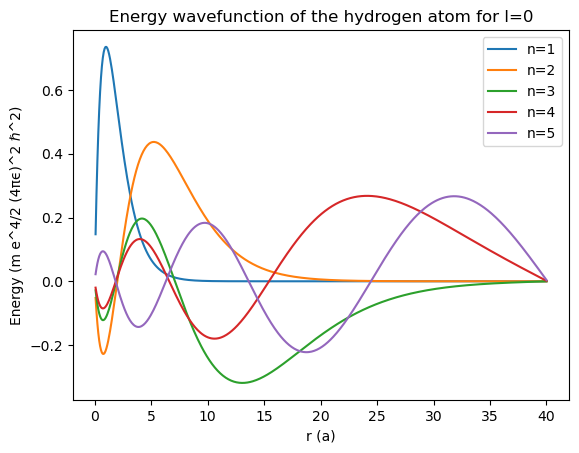

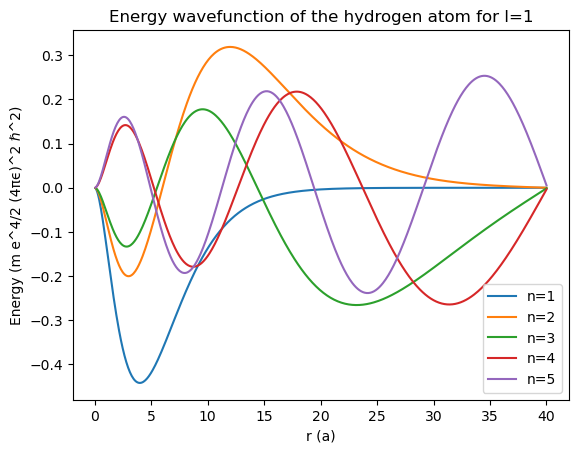

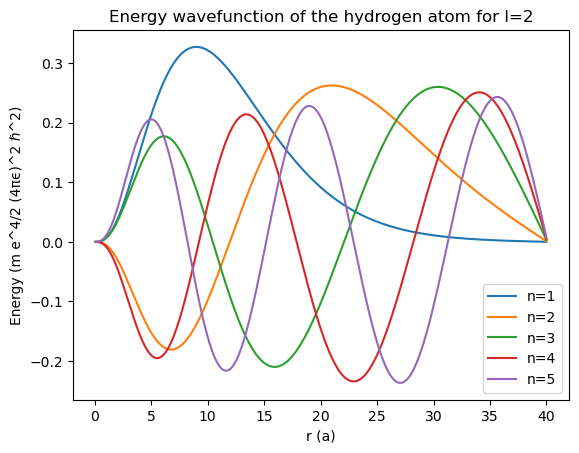

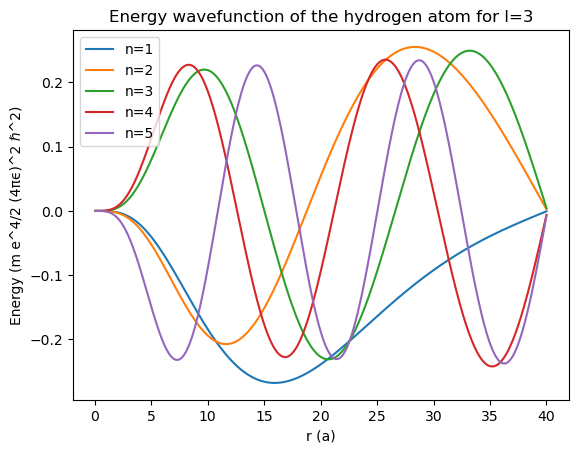

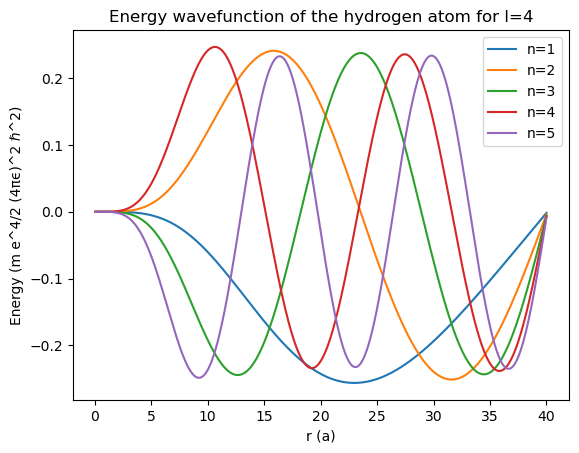

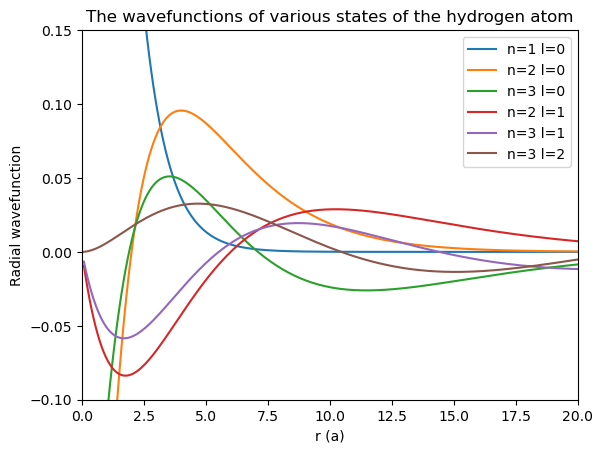

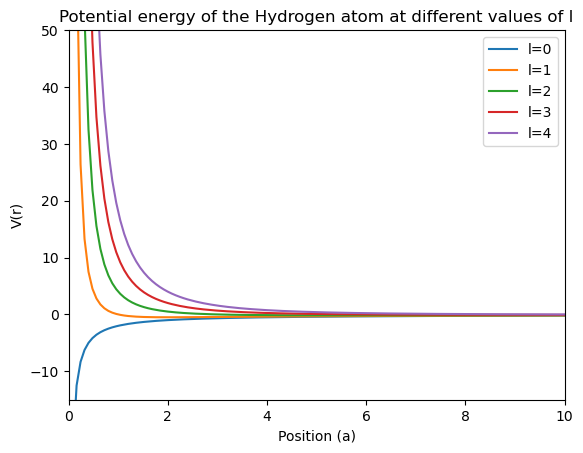

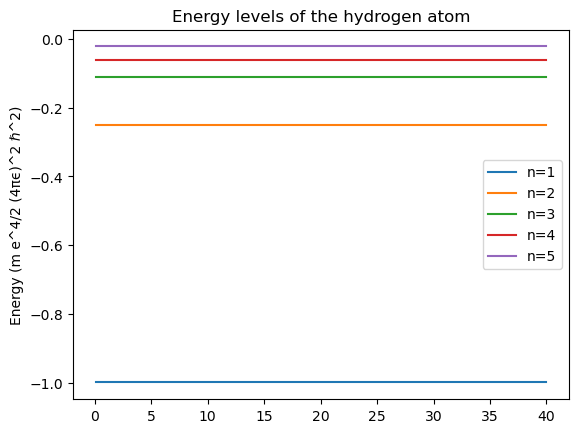

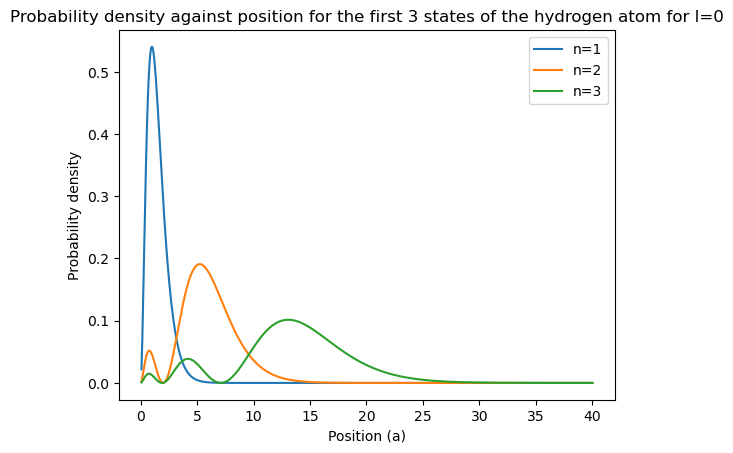

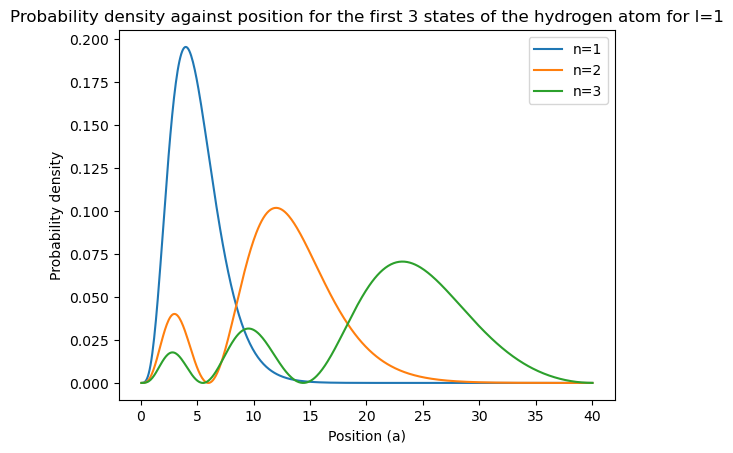

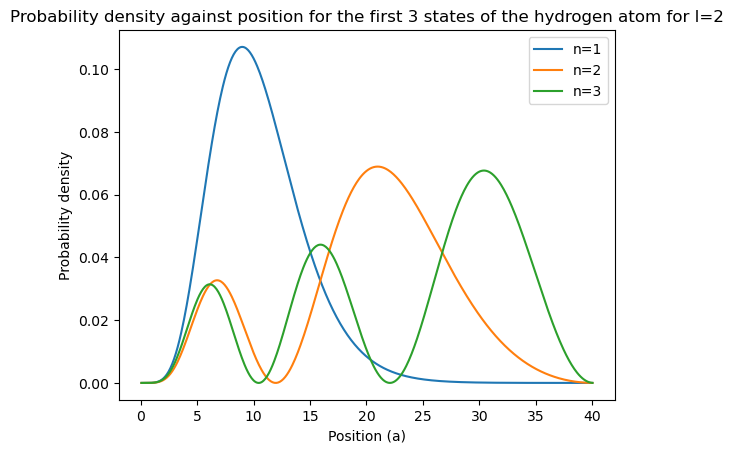

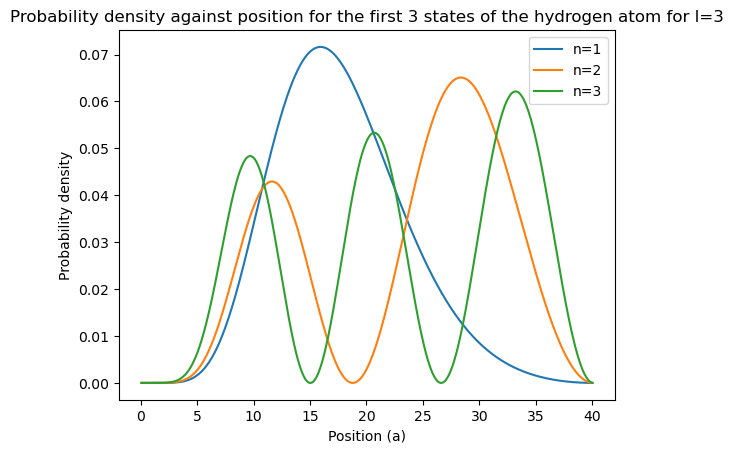

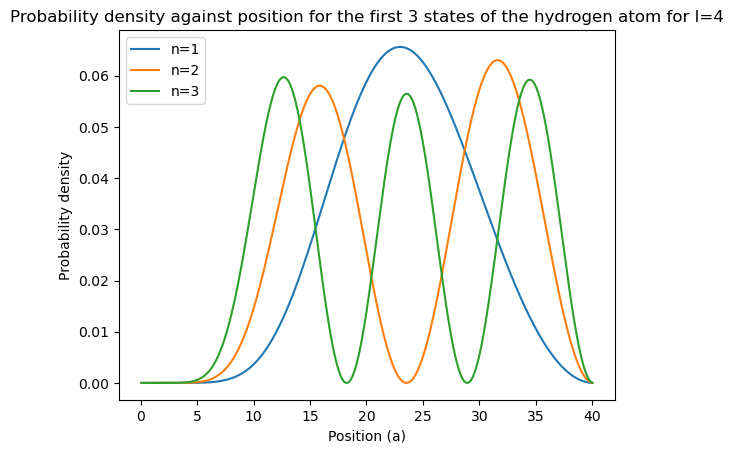

In [2]:
## The Hydrogen Atom ##

def kinetic_energy(N,delta_r):
    """
    This function takes an integer N of the number of discrete points the kinetic energy will be evaluated at, and an integer delta_r of the spacing between each discrete position that the kinetic energy will be evaluated for
    It then uses the method outlined in the assignemnt brief to produce and return a kinetic energy matrix, in the form of an NxN array
    """ 
    ## finding the kinetic energy
    kinetic_energy = np.zeros([N,N]) #creates an NxN numpy array to store the kinetic energy matrix that will be used to compute the hamiltonian
    for i in range (N):
        kinetic_energy[i,i] = 2/(delta_r**2) #sets every value in the main diaganol to 2/delta r^2, as described in the assignment brief
        if i<(N-1):
            kinetic_energy[i,i+1] = (-1)/(delta_r**2) #sets every value on the diagonals either side of this to -1/delta r^2, as described in the assignment brief
        if i>0:
            kinetic_energy[i,i-1] = (-1)/(delta_r**2)
    return kinetic_energy
        
def potential_energy(N,r_i,l):
    """
    This function takes an integer N of the number of discrete points the kinetic energy will be evaluated at, an array r_i containing each discrete position at which the potential energy will be calculated, andan integer l which represents the quantum number l that we desire the potnential of
    It then uses the method outlined in the assignemnt brief to produce and return a potential energy matrix, in the form of an NxN array
    """
    ## finding the potential energy
    potential_energy = np.zeros([N,N]) #uses equation (1.11) from the assignment brief to create an array with the potential energy at each discrete point along the diaganol
    for i in range (N):
        potential_energy[i,i] = (-2/r_i[i]) + l*(l+1)/(r_i[i]**2)
    return potential_energy

def hamiltonian (N,delta_r,l,r_i):
    """
    This function simply gets passed all of the variables required to call the kinetic and potential energy functions and adds the returned arrays 
    It then returns the sum of these as the hamiltonian matrix
    """
    hamiltonian = potential_energy(N,r_i,l) + kinetic_energy(N,delta_r) #sums the potential and kinetic energies produced by the above functions. These have been written as separate functions so that the potential energy can be plotted alone
    return hamiltonian

def plot_H(x_vals,y_vals,x_name,y_name,plot_name,state):
    """
    This function produces a plot of a chosen amount of wavefunctions or probability densities at different energy levels of the hydrogen atom
    In order to do so this function takes an array of values to be plotted on the x axis, an array of values to be plotted on the y axis, a label for the x and y axes, a title for the graph, and the number of states that should be plotted
    Unlike in the first part, a function has been implemented for these plots for neatness as a graph for 5 values of l will be plotted
    """
    for i in range (state):
        name = 'n='+str(i+1) #sets the label of each state to be one higher than the iterated variable as the ground state of the hydrogen atom is n=1
        plt.plot(x_vals,y_vals[:,i],label=name) #selects the ith list in the array to be plotted on each iteration in order to display many states of the hydrogen atom at once
    #the indexing in the plotting here differs from that of the QHO plots due to the different numerical methods used arranging the arrays in different ways
    plt.xlabel(x_name)
    plt.ylabel(y_name)
    plt.title(plot_name)
    plt.legend()
    plt.show()

## defining variables
N = 500 #increases N as the numerical method used in this section take cope with many more calculations
r = 40
r_min = r/(N) #minimum radius set as if r=0 at any point we have a division by 0
r_i = np.linspace(r_min,r,N) #creates an array containing the value of r at each discrete point
delta_r = (r-r_min)/(N-1)
l = np.arange(5) #sets the values of l for the hydrogen atom

## finding the hamiltonian
H_hamiltonian_0 = hamiltonian(N,delta_r,l[0],r_i) #uses the above functions to construct the hamiltonian matrix for five different values of l
H_hamiltonian_1 = hamiltonian(N,delta_r,l[1],r_i) #in this part of the assignment the calculation of the hamiltonian has been written as functions as this is neater and less error prone when calculating the hamiltonian for 5 different values of l
H_hamiltonian_2 = hamiltonian(N,delta_r,l[2],r_i)
H_hamiltonian_3 = hamiltonian(N,delta_r,l[3],r_i)
H_hamiltonian_4 = hamiltonian(N,delta_r,l[4],r_i)

## finding eigenvalues and eigenvectors
H_energies_0, H_wavefunctions_0 = scipy.sparse.linalg.eigsh(H_hamiltonian_0,k=6,which='SA') #this uses a built in function from the SciPy library to find the first 6 eigensolutions for different values of l
H_energies_1, H_wavefunctions_1 = scipy.sparse.linalg.eigsh(H_hamiltonian_1,k=6,which='SA') #this SciPy function has been used as the hamiltonian matrix is large and sparse, meaning this function is most efficient
H_energies_2, H_wavefunctions_2 = scipy.sparse.linalg.eigsh(H_hamiltonian_2,k=6,which='SA') #a different numerical method has been used here than in the first part for efficiency and comparison purposes
H_energies_3, H_wavefunctions_3 = scipy.sparse.linalg.eigsh(H_hamiltonian_3,k=6,which='SA')
H_energies_4, H_wavefunctions_4 = scipy.sparse.linalg.eigsh(H_hamiltonian_4,k=6,which='SA')

## checking results
if np.allclose(H_hamiltonian_0, H_hamiltonian_0.T):
    print('Hamiltonian is hermitian') #this checks if the hamiltonian is hermition by comparing it to itself transposed, np.allclose() is used as due to binary rounding errors the matrices will never be perfectly accurate

## normalising the wavefunctions
for i in range(5): #ensures normalisation of each wavefunction 
    norm = np.sum(H_wavefunctions_0[:,i]**2) * delta_r #calculates the normalisation factor required for each state
    H_wavefunctions_0[:,i] /= np.sqrt(norm) #divies by this factor to normalise the state

for i in range(5): 
    norm = np.sum(H_wavefunctions_1[:,i]**2) * delta_r 
    H_wavefunctions_1[:,i] /= np.sqrt(norm)
    
for i in range(5): 
    norm = np.sum(H_wavefunctions_2[:,i]**2) * delta_r 
    H_wavefunctions_2[:,i] /= np.sqrt(norm)
    
for i in range(5): 
    norm = np.sum(H_wavefunctions_3[:,i]**2) * delta_r 
    H_wavefunctions_3[:,i] /= np.sqrt(norm)
    
for i in range(5): 
    norm = np.sum(H_wavefunctions_4[:,i]**2) * delta_r 
    H_wavefunctions_4[:,i] /= np.sqrt(norm)

## calculating the probability densities
H_probability_density_0 = (H_wavefunctions_0)**2 #calculates the probability density of each hydrogen atom state investigated by squaring each wavefunction
H_probability_density_1 = (H_wavefunctions_1)**2
H_probability_density_2 = (H_wavefunctions_2)**2
H_probability_density_3 = (H_wavefunctions_3)**2
H_probability_density_4 = (H_wavefunctions_4)**2

## displaying results
for i in range (5):
    print('Energy at n =',i+1,H_energies_0[i],'(m e^4/2 (4πϵ)^2 ℏ^2), Expected value:',(-1)/(i+1)**2,'(m e^4/2 (4πϵ)^2 ℏ^2), Percentage error',(((-1)/(i+1)**2-H_energies_0[i])/(-1)/(i+1)**2)*100) #prints the first 6 energy levels of the hydrogen atom when l=0 so they can be compared to the known energies of the hydrogen atom

## plotting results
plot_H(r_i,H_wavefunctions_0,'r (a)','Energy (m e^4/2 (4πϵ)^2 ℏ^2)','Energy wavefunction of the hydrogen atom for l=0',5) #calls the plotting function to produce plots for each value of l we found eigenvectors for
plot_H(r_i,H_wavefunctions_1,'r (a)','Energy (m e^4/2 (4πϵ)^2 ℏ^2)','Energy wavefunction of the hydrogen atom for l=1',5)
plot_H(r_i,H_wavefunctions_2,'r (a)','Energy (m e^4/2 (4πϵ)^2 ℏ^2)','Energy wavefunction of the hydrogen atom for l=2',5)
plot_H(r_i,H_wavefunctions_3,'r (a)','Energy (m e^4/2 (4πϵ)^2 ℏ^2)','Energy wavefunction of the hydrogen atom for l=3',5)
plot_H(r_i,H_wavefunctions_4,'r (a)','Energy (m e^4/2 (4πϵ)^2 ℏ^2)','Energy wavefunction of the hydrogen atom for l=4',5)

plt.figure() #this graph has been produced in addition to those above for comparison to scientific literature
plt.plot(r_i,H_wavefunctions_0[:,0]/r_i,label='n=1 l=0') #these wavefunctions have been divided by r in order to plot R(r), the full radial wavefunction, rather than u(r), the solution to the hydrogen atom schrodinger equation
plt.plot(r_i,H_wavefunctions_0[:,1]/r_i,label='n=2 l=0')
plt.plot(r_i,H_wavefunctions_0[:,2]/r_i,label='n=3 l=0')
plt.plot(r_i,H_wavefunctions_1[:,1]/r_i,label='n=2 l=1')
plt.plot(r_i,H_wavefunctions_1[:,2]/r_i,label='n=3 l=1')
plt.plot(r_i,H_wavefunctions_2[:,2]/r_i,label='n=3 l=2')
plt.xlabel('r (a)')
plt.ylabel('Radial wavefunction')
plt.xlim(0,20)
plt.ylim(-0.1,0.15)
plt.title('The wavefunctions of various states of the hydrogen atom')
plt.legend()
plt.show()

plt.figure()
for i in range (5):
    name = 'l='+str(i)
    plt.plot(r_i,np.diag(potential_energy(N,r_i,l[i])), label=name) #plots the potential energy against position for each value of l investigated to give further insight into how this quantum number affects the state of the hydrogen atom
plt.xlabel('Position (a)')
plt.ylabel('V(r)')
plt.xlim(0,10) #this shortens the x axis for clearer visualisation of the potentials
plt.ylim(-15,50)
plt.legend()
plt.title('Potential energy of the Hydrogen atom at different values of l')
plt.show()

plt.figure()
for r in range (5):
    name = 'n='+str(r+1)
    plt.plot(r_i, np.ones(len(r_i))*H_energies_0[r], label = name) #plots and labels the energy levels of the hydrogen atom when l=0 so we can better visualisation the quantisation of the energy levels 
plt.ylabel('Energy (m e^4/2 (4πϵ)^2 ℏ^2)')
plt.title('Energy levels of the hydrogen atom')
plt.legend()
plt.show()

plot_H(r_i,H_probability_density_0,'Position (a)','Probability density','Probability density against position for the first 3 states of the hydrogen atom for l=0',3) #calls the plotting function to produce plots for each value of l we found eigenvectors for
plot_H(r_i,H_probability_density_1,'Position (a)','Probability density','Probability density against position for the first 3 states of the hydrogen atom for l=1',3)
plot_H(r_i,H_probability_density_2,'Position (a)','Probability density','Probability density against position for the first 3 states of the hydrogen atom for l=2',3)
plot_H(r_i,H_probability_density_3,'Position (a)','Probability density','Probability density against position for the first 3 states of the hydrogen atom for l=3',3)
plot_H(r_i,H_probability_density_4,'Position (a)','Probability density','Probability density against position for the first 3 states of the hydrogen atom for l=4',3)
